# 02 – Model comparison

**CT4101 Machine Learning Portfolio Project – Milestone 3 (Model Comparison Checkpoint)**

**Question:** Based on a set of features describing a website's URL, domain and page behaviour, can a model determine
whether a site is phishing or legitimate, without missing many phishing sites?

This notebook continues from `data_baseline.ipynb` (Milestone 2). It uses **exactly the same cleaned data, train/test
split and 5 cross-validation folds**, so the learned models are compared with the baseline under the same protocol.

Contents:
1. Setup
2. Data and split (repeated from Milestone 2)
3. Evaluation protocol and tuning
4. Models and search grids
5. Results table
6. Final model settings
7. Visualisations (ROC / precision–recall curves, confusion matrix, feature importance)
8. Error analysis
9. Draft conclusion

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             confusion_matrix)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import FEATURE_NAMES, TARGET_NAME, load_dataset

RANDOM_STATE = 42      # same seed as Milestone 2, so the split and folds are identical
TEST_SIZE = 0.20
N_FOLDS = 5
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = PROJECT_ROOT / "reports"

pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Data and split (repeated from Milestone 2)

Same steps as `data_baseline.ipynb`: drop exact duplicate rows **before** splitting (to stop identical rows appearing in
both train and test), recode the target so phishing = 1, then a stratified 80/20 split with the same seed.

In [2]:
raw = load_dataset()
data = raw.drop_duplicates().reset_index(drop=True)
X = data[FEATURE_NAMES]
y = (data[TARGET_NAME] == -1).astype(int).rename("is_phishing")   # 1 = phishing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
outer_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)  # same folds as the baseline

print(f"Training set: {len(X_train)} rows   Test set (held out, not used here): {len(X_test)} rows")

Training set: 4679 rows   Test set (held out, not used here): 1170 rows


## 3. Evaluation protocol and tuning

- **Comparison:** every model, including the baseline, is scored on the **same 5 stratified folds** of the training
  set that were used for the baseline in Milestone 2. Metrics: recall, precision, F1 and ROC-AUC on the phishing class,
  plus accuracy for context.
- **Tuning (nested cross-validation):** hyperparameters are chosen by a small grid search (`GridSearchCV`) with its
  own 3-fold CV, run **inside** each of the 5 outer training folds. The outer validation fold is never seen during
  tuning, so the scores in the results table are not inflated by the tuning. Picking hyperparameters on the same folds
  used to report scores would make every tuned model look slightly better than it really is.
- **Tuning metric: F1.** Recall is the most important metric, but the Milestone 2 baseline showed that recall alone
  rewards a model that calls everything phishing (recall 1.0, but useless). F1 balances catching phishing sites against
  false alarms. Recall is still reported and used when interpreting the results.
- **Test set:** still untouched. It will be used once, for the final evaluation of the chosen model in the final
  submission.

## 4. Models and search grids

All learned models use the same one-hot preprocessing as Milestone 2, inside a `Pipeline`, so the encoder is fitted on
training folds only.

| Model | Why it is included | Hyperparameters searched |
|---|---|---|
| Majority class (baseline) | Minimum bar to beat | none |
| Logistic regression | Simple, interpretable linear model | `C` (regularisation strength): 0.01, 0.1, 1, 10 |
| k-nearest neighbours | Distance-based, no training assumptions | `n_neighbors`: 3, 5, 11, 21; `weights`: uniform, distance |
| Decision tree | Interpretable rules; non-linear | `max_depth`: 3, 5, 10, None; `min_samples_leaf`: 1, 5, 20 |
| Random forest | Ensemble of trees; usually stronger than one tree | `max_depth`: None, 15; `min_samples_leaf`: 1, 3 (300 trees) |

The grids are deliberately small: the aim is a fair, explainable comparison rather than squeezing out the last 0.1%.

In [3]:
def make_preprocessor():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def make_pipeline(model):
    return Pipeline([("preprocess", make_preprocessor()), ("model", model)])

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "k-NN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 11, 21], "model__weights": ["uniform", "distance"]},
    ),
    "Decision tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 10, None], "model__min_samples_leaf": [1, 5, 20]},
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [None, 15], "model__min_samples_leaf": [1, 3]},
    ),
}

def make_search(model, grid):
    return GridSearchCV(make_pipeline(model), grid, scoring="f1", cv=inner_cv, n_jobs=-1)

## 5. Results table

This cell runs the nested cross-validation for every model. It takes about a minute, mostly for the random forest.

In [4]:
scoring = ["recall", "precision", "f1", "roc_auc", "accuracy"]
fold_scores = {}      # raw per-fold scores, used for the table and the fold-by-fold comparison
chosen_params = {}    # hyperparameters picked inside each outer fold

baseline = make_pipeline(DummyClassifier(strategy="most_frequent"))
fold_scores["Majority class (baseline)"] = cross_validate(baseline, X_train, y_train, cv=outer_cv, scoring=scoring)

for name, (model, grid) in models.items():
    scores = cross_validate(make_search(model, grid), X_train, y_train, cv=outer_cv,
                            scoring=scoring, return_estimator=True)
    fold_scores[name] = scores
    chosen_params[name] = [est.best_params_ for est in scores["estimator"]]

results = pd.DataFrame({
    name: {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}
    for name, s in fold_scores.items()
}).T
results.to_csv(RESULTS_DIR / "model_comparison_cv_results.csv")
results

,recall,precision,f1,roc_auc,accuracy
Majority class (baseline),1.000 ± 0.000,0.516 ± 0.000,0.681 ± 0.000,0.500 ± 0.000,0.516 ± 0.000
Logistic regression,0.930 ± 0.008,0.947 ± 0.007,0.939 ± 0.005,0.985 ± 0.003,0.937 ± 0.005
k-NN,0.932 ± 0.007,0.947 ± 0.014,0.939 ± 0.008,0.981 ± 0.004,0.938 ± 0.009
Decision tree,0.908 ± 0.007,0.936 ± 0.016,0.922 ± 0.010,0.970 ± 0.012,0.920 ± 0.011
Random forest,0.946 ± 0.011,0.956 ± 0.008,0.951 ± 0.004,0.990 ± 0.002,0.949 ± 0.004


In [5]:
# Fold-by-fold F1, to check whether the differences between models are consistent or just noise
f1_by_fold = pd.DataFrame({name: s["test_f1"] for name, s in fold_scores.items()},
                          index=[f"fold {i}" for i in range(1, N_FOLDS + 1)]).round(3)
f1_by_fold

,Majority class (baseline),Logistic regression,k-NN,Decision tree,Random forest
fold 1,0.681,0.937,0.932,0.927,0.952
fold 2,0.681,0.934,0.948,0.915,0.947
fold 3,0.681,0.939,0.945,0.932,0.955
fold 4,0.681,0.949,0.944,0.930,0.955
fold 5,0.681,0.936,0.927,0.906,0.944


In [6]:
diff = f1_by_fold["Random forest"] - f1_by_fold["Logistic regression"]
print(f"Random forest minus logistic regression, F1 per fold: {diff.round(3).tolist()}")
print(f"Random forest better in {(diff > 0).sum()} of {N_FOLDS} folds; mean difference {diff.mean():.3f}")

Random forest minus logistic regression, F1 per fold: [0.015, 0.013, 0.016, 0.006, 0.008]
Random forest better in 5 of 5 folds; mean difference 0.012


**Reading the table.** All four learned models are far above the baseline (F1 ≈ 0.68, ROC-AUC 0.5). The
**random forest is the best learned model on every metric**, with recall ≈ 0.95 and ROC-AUC ≈ 0.99 (the baseline's
recall of 1.0 is higher only because it labels every site as phishing). Logistic regression and k-NN
are close behind, and a single decision tree is the weakest learned model. The fold-by-fold check shows that the
random forest beats logistic regression in every fold, so the gap is small but consistent rather than chance.

## 6. Final model settings

Hyperparameters chosen inside each outer fold (shows how stable the tuning is):

In [7]:
pd.DataFrame({name: [", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items()) for p in params]
              for name, params in chosen_params.items()},
             index=[f"fold {i}" for i in range(1, N_FOLDS + 1)])

,Logistic regression,k-NN,Decision tree,Random forest
fold 1,C=1,"n_neighbors=5, weights=uniform","max_depth=10, min_samples_leaf=1","max_depth=15, min_samples_leaf=1"
fold 2,C=1,"n_neighbors=11, weights=uniform","max_depth=10, min_samples_leaf=1","max_depth=None, min_samples_leaf=1"
fold 3,C=0.1,"n_neighbors=11, weights=uniform","max_depth=10, min_samples_leaf=5","max_depth=15, min_samples_leaf=1"
fold 4,C=0.1,"n_neighbors=3, weights=uniform","max_depth=10, min_samples_leaf=20","max_depth=None, min_samples_leaf=1"
fold 5,C=1,"n_neighbors=11, weights=uniform","max_depth=10, min_samples_leaf=5","max_depth=15, min_samples_leaf=1"


Most settings are stable across folds. Where they vary, it is only between neighbouring options (e.g. random-forest
`max_depth` 15 vs unlimited, k-NN with 3, 5 or 11 neighbours), and the outer-fold scores stay similar either way,
so the exact choice makes little difference.

The **final settings** for each model come from re-running the grid search once on the whole training set. These
fitted models are used for the plots and error analysis below.

In [8]:
final_models = {}
for name, (model, grid) in models.items():
    search = make_search(model, grid).fit(X_train, y_train)
    final_models[name] = search.best_estimator_
    print(f"{name:20s} {search.best_params_}   (inner-CV F1 = {search.best_score_:.3f})")

Logistic regression  {'model__C': 1}   (inner-CV F1 = 0.939)


k-NN                 {'model__n_neighbors': 11, 'model__weights': 'uniform'}   (inner-CV F1 = 0.936)


Decision tree        {'model__max_depth': 10, 'model__min_samples_leaf': 1}   (inner-CV F1 = 0.923)


Random forest        {'model__max_depth': 15, 'model__min_samples_leaf': 1}   (inner-CV F1 = 0.947)


## 7. Visualisations

For the plots and the error analysis I use **out-of-fold predictions**: each training row is predicted by a model
that did not see that row, using the same 5 outer folds. The final settings were picked using the whole training set,
so these are slightly optimistic, but they are fine for comparing models and finding where errors happen.
The test set is still not used.

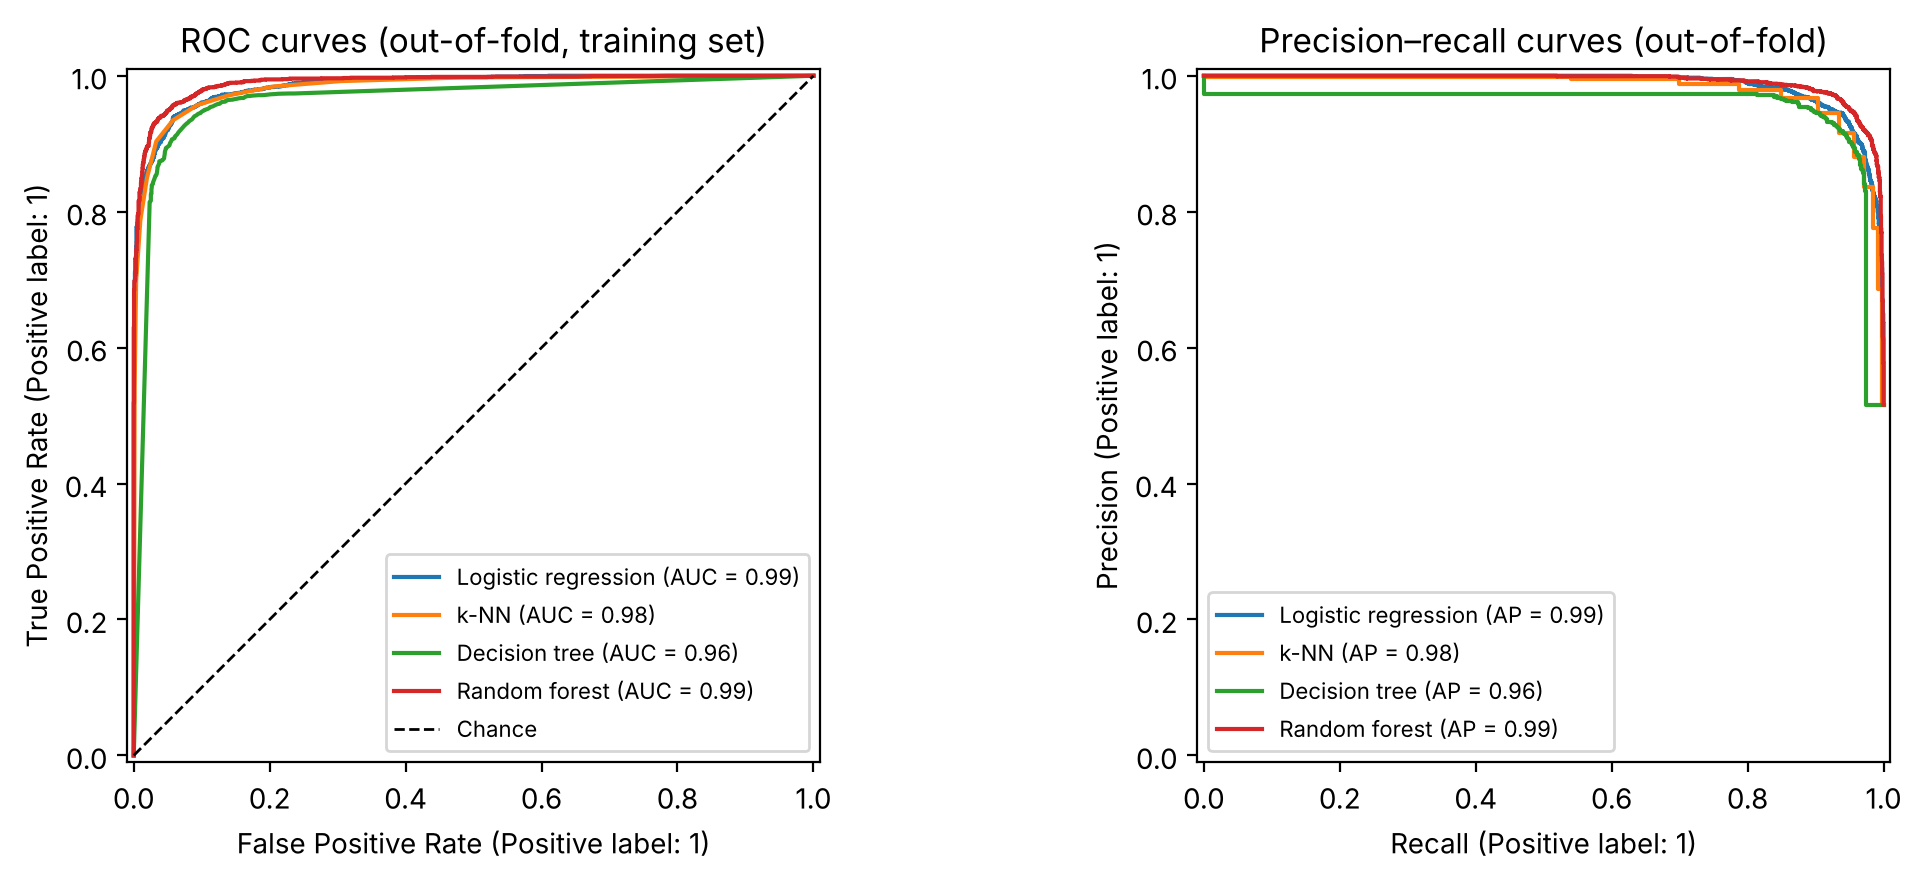

In [9]:
oof_proba = {name: cross_val_predict(est, X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]
             for name, est in final_models.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, proba in oof_proba.items():
    RocCurveDisplay.from_predictions(y_train, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_train, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set_title("ROC curves (out-of-fold, training set)")
axes[1].set_title("Precision–recall curves (out-of-fold)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

The curves of the four models are close together and all hug the top-left (ROC) / top-right (PR) corner. The random
forest's curve is highest; the decision tree's is lowest and more jagged because a single tree outputs only a few
distinct probabilities.

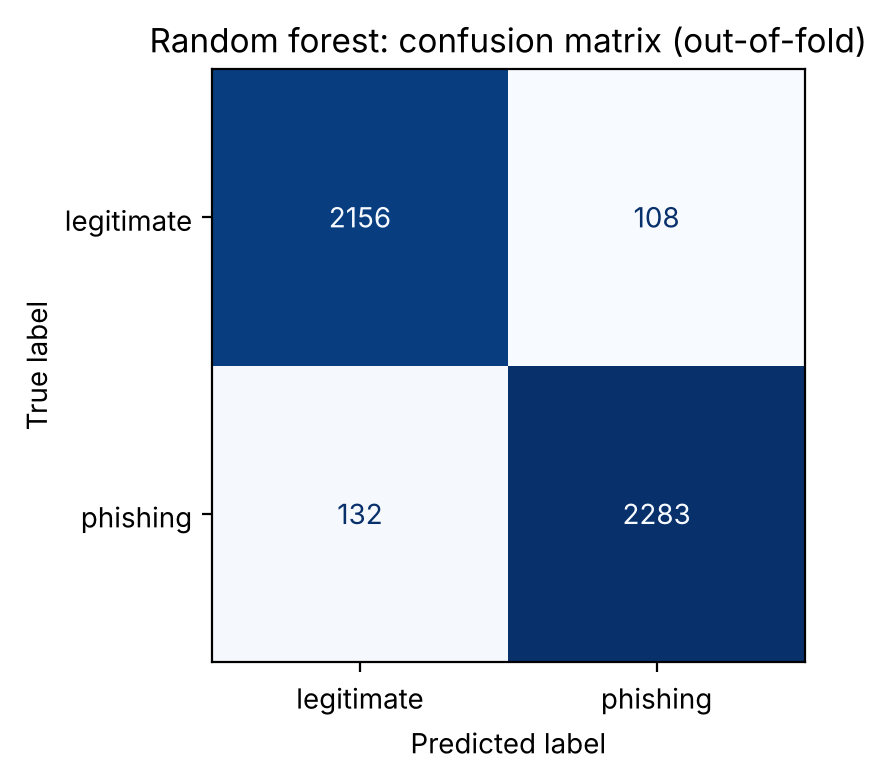

Missed phishing sites (false negatives): 132 of 2415 (5.5%)
False alarms on legitimate sites (false positives): 108 of 2264 (4.8%)


In [10]:
BEST = "Random forest"
oof_pred = (oof_proba[BEST] >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["legitimate", "phishing"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"{BEST}: confusion matrix (out-of-fold)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_random_forest.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_train, oof_pred).ravel()
print(f"Missed phishing sites (false negatives): {fn} of {fn + tp} ({fn / (fn + tp):.1%})")
print(f"False alarms on legitimate sites (false positives): {fp} of {fp + tn} ({fp / (fp + tn):.1%})")

**Feature importance.** I use *permutation importance*: shuffle one feature's values and measure how much F1 drops.
It is computed on each outer validation fold (with a model trained on the other folds) and averaged, so it reflects
data the model did not train on. It also works on the original 30 features, rather than the one-hot columns.

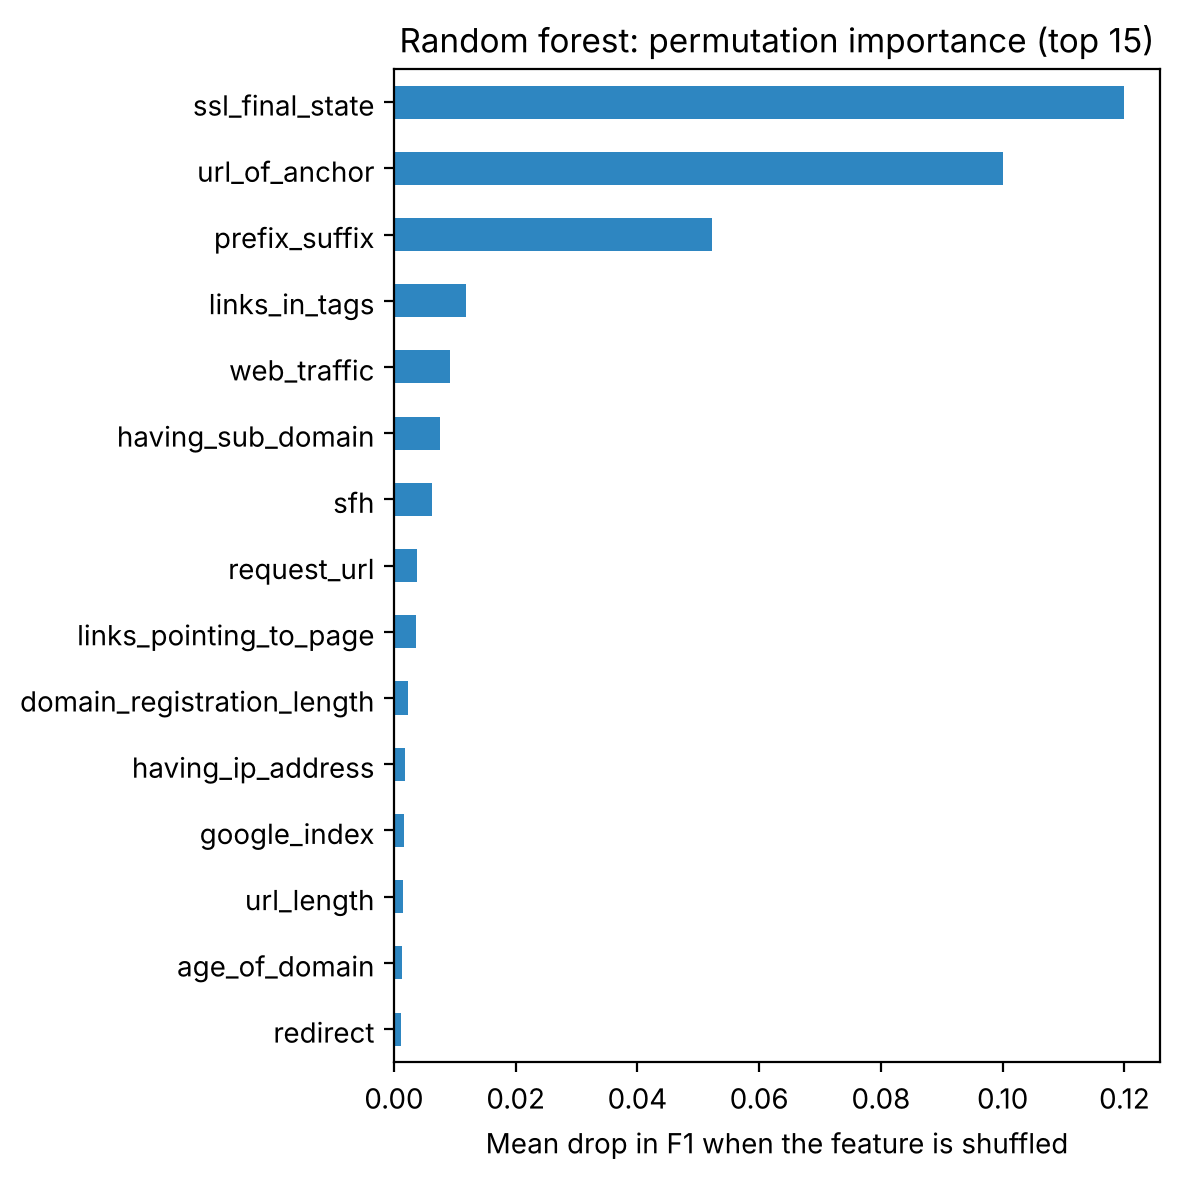

In [11]:
fold_importances = []
for train_idx, val_idx in outer_cv.split(X_train, y_train):
    est = clone(final_models[BEST]).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    pi = permutation_importance(est, X_train.iloc[val_idx], y_train.iloc[val_idx], scoring="f1",
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    fold_importances.append(pi.importances_mean)
importance = pd.Series(np.mean(fold_importances, axis=0), index=FEATURE_NAMES).sort_values()

fig, ax = plt.subplots(figsize=(6, 6))
importance.tail(15).plot.barh(ax=ax, color="#2e86c1")
ax.set_xlabel("Mean drop in F1 when the feature is shuffled")
ax.set_title(f"{BEST}: permutation importance (top 15)")
plt.tight_layout()
plt.savefig(FIG_DIR / "permutation_importance_random_forest.png", dpi=150)
plt.show()

Two features dominate: **`ssl_final_state`** (whether the site uses HTTPS with a trusted, established certificate)
and **`url_of_anchor`** (how many of the page's links point to other domains or nowhere), followed by
**`prefix_suffix`** (a "-" in the domain name). Most other features add little on their own once these are known.

## 8. Error analysis

Where does the best model (random forest) go wrong? I look at its out-of-fold errors on the training set.

In [12]:
errors = X_train.assign(actual=y_train, predicted=oof_pred)
errors["outcome"] = np.select(
    [(errors.actual == 1) & (errors.predicted == 0), (errors.actual == 0) & (errors.predicted == 1)],
    ["missed phishing (FN)", "false alarm (FP)"], default="correct")

# Rows whose feature pattern appears with BOTH labels in the data (identical inputs, different answers)
label_count = data.groupby(FEATURE_NAMES)[TARGET_NAME].nunique()
conflicting = label_count[label_count > 1].index
errors["conflicting_pattern"] = X_train.set_index(FEATURE_NAMES).index.isin(conflicting)

pd.crosstab(errors["outcome"], errors["conflicting_pattern"], margins=True)

conflicting_pattern,False,True,All
outcome,,,
correct,4413,26,4439
false alarm (FP),69,39,108
missed phishing (FN),97,35,132
All,4579,100,4679


In [13]:
n_errors = (errors.outcome != "correct").sum()
n_unavoidable = ((errors.outcome != "correct") & errors.conflicting_pattern).sum()
print(f"{n_unavoidable} of {n_errors} errors ({n_unavoidable / n_errors:.0%}) are on conflicting patterns "
      "that no model could get fully right")

74 of 240 errors (31%) are on conflicting patterns that no model could get fully right


In [14]:
def error_breakdown(feature):
    return (errors.groupby(feature)
            .agg(rows=("actual", "size"),
                 phishing_share=("actual", "mean"),
                 error_rate=("outcome", lambda s: (s != "correct").mean()),
                 missed_phishing=("outcome", lambda s: (s == "missed phishing (FN)").sum()),
                 false_alarms=("outcome", lambda s: (s == "false alarm (FP)").sum()))
            .round(3))

print("ssl_final_state  (-1 = no/untrusted HTTPS, 0 = suspicious, 1 = trusted HTTPS)")
display(error_breakdown("ssl_final_state"))
print("url_of_anchor  (-1 = most links external/empty, 0 = mixed, 1 = few)")
display(error_breakdown("url_of_anchor"))

ssl_final_state  (-1 = no/untrusted HTTPS, 0 = suspicious, 1 = trusted HTTPS)


,rows,phishing_share,error_rate,missed_phishing,false_alarms
ssl_final_state,,,,,
-1,1719,0.874,0.051,21,66
0,583,0.990,0.003,0,2
1,2377,0.141,0.064,111,40


url_of_anchor  (-1 = most links external/empty, 0 = mixed, 1 = few)


,rows,phishing_share,error_rate,missed_phishing,false_alarms
url_of_anchor,,,,,
-1,1610,0.989,0.001,0,1
0,2112,0.339,0.104,117,103
1,957,0.111,0.020,15,4


**Where the model performs poorly**

1. **Phishing sites with trusted HTTPS.** 111 of the 132 missed phishing sites (84%) have `ssl_final_state = 1`. Because a
   valid certificate is the strongest "legitimate" signal in this data, phishing sites that have one look legitimate to
   the model. This is the most worrying weakness, because phishing sites with valid HTTPS certificates have become
   common since this data was collected (free certificates), so this error type would probably be **more frequent on
   current websites** than these scores suggest.
2. **"Suspicious" middle values.** 220 of the 240 errors (92%, both kinds) have `url_of_anchor = 0`, the mixed/suspicious
   category. When the strongest features are ambiguous, the classes overlap and the model has little to go on.
3. **Label noise.** Around a third of the errors are on feature patterns that appear with both labels in the data.
   These cannot be fixed by a better model, only by richer features (e.g. the raw URL or page content, which this
   dataset does not include).

## 9. Draft conclusion

**Current best model: random forest** (300 trees, settings tuned by nested CV; see Section 6).

**Evidence.** Under the same 5-fold protocol as the baseline, it has the best mean score of the learned models on every metric
(recall ≈ 0.95, precision ≈ 0.96, F1 ≈ 0.95, ROC-AUC ≈ 0.99), it beats logistic regression in every fold,
and every learned model is far above the majority-class baseline (F1 ≈ 0.68, ROC-AUC 0.5).
**Logistic regression** is a close second and is much simpler and easier to explain, so it is a reasonable
alternative if interpretability matters more than about one point of F1.

**Limitations.**
- The model misses about 5.5% of phishing sites in cross-validation, mostly ones with trusted HTTPS, a type of phishing
  that is more common today than when the data was collected (2012–2015). Real-world performance is likely lower.
- About a third of errors come from identical feature patterns with different labels, which caps achievable accuracy.
- The features were pre-encoded by the dataset authors, so I cannot add new information from the URLs themselves.
- Scores are from cross-validation on the training set; the held-out test set has not been used yet.
- Removing duplicates means performance is measured on distinct feature patterns, not on how often each pattern
  occurs in practice.

**Next steps (final submission).**
- Evaluate the chosen model **once** on the held-out test set and compare with the CV estimate.
- Consider lowering the decision threshold below 0.5 to raise recall (fewer missed phishing sites), using the
  precision–recall curve to choose a threshold on the training data, and report the cost in false alarms.
- Discuss the responsible-use issues (concept drift, false negatives giving false confidence, evasion by attackers
  who know which features matter).